In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
%matplotlib inline

In [5]:
# Read dataset
shop_data = pd.read_csv('online_shoppers.csv')
print(shop_data.shape)
shop_data.head()

(999999, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType,Month,VisitorType,Weekend,Revenue
0,0,0.000000,0,0.000000,0,0.000000,0.016765,0.085003,3.191731,0.000000,2,1,1,1,Nov,Returning_Visitor,False,False
1,3,140.433150,0,121.793138,55,2333.187358,0.000000,0.034682,0.000000,0.221186,3,3,3,5,Dec,Returning_Visitor,False,False
2,2,169.063012,1,72.697027,23,1448.426947,0.068493,0.075369,0.000000,0.000000,2,2,2,12,Sep,Returning_Visitor,False,False
3,4,129.698301,1,118.581521,53,1238.760755,0.024336,0.049339,14.476824,0.124415,1,1,4,8,May,New_Visitor,False,False
4,2,214.526081,2,235.043689,37,297.590433,0.001517,0.018661,37.270547,0.071883,3,4,5,9,Nov,Returning_Visitor,False,True


In [6]:
# Info + Missing values + Duplicates
shop_data.info()
print("\nMissing values:\n", shop_data.isnull().sum())
print("\nDuplicated rows:", shop_data.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 999999 entries, 0 to 999998
Data columns (total 18 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Administrative           999999 non-null  int64  
 1   Administrative_Duration  999999 non-null  float64
 2   Informational            999999 non-null  int64  
 3   Informational_Duration   999999 non-null  float64
 4   ProductRelated           999999 non-null  int64  
 5   ProductRelated_Duration  999999 non-null  float64
 6   BounceRates              999999 non-null  float64
 7   ExitRates                999999 non-null  float64
 8   PageValues               999999 non-null  float64
 9   SpecialDay               999999 non-null  float64
 10  OperatingSystems         999999 non-null  int64  
 11  Browser                  999999 non-null  int64  
 12  Region                   999999 non-null  int64  
 13  TrafficType              999999 non-null  int64  
 14  Month          

In [7]:
# Statistical summary
display(shop_data.describe().T)
display(shop_data.describe(exclude=np.number).T)

,count,mean,std,min,25%,50%,75%,max
Administrative,999999.0,2.780929,2.679913,0.0,0.000000,2.000000,5.000000,20.000000
Administrative_Duration,999999.0,117.859962,130.018648,0.0,0.000000,79.661895,198.785702,1179.088209
Informational,999999.0,0.782443,0.953054,0.0,0.000000,0.000000,1.000000,7.000000
Informational_Duration,999999.0,74.695244,94.262121,0.0,0.000000,33.858389,127.585937,875.337147
ProductRelated,999999.0,37.609186,36.208370,0.0,2.000000,31.000000,60.000000,299.000000
ProductRelated_Duration,999999.0,1496.799697,1507.551284,0.0,0.000000,1170.143584,2449.121147,12125.673897
BounceRates,999999.0,0.031455,0.036899,0.0,0.000000,0.017177,0.053225,0.200000
ExitRates,999999.0,0.047372,0.042088,0.0,0.011138,0.038529,0.074927,0.200000
PageValues,999999.0,8.854572,15.863277,0.0,0.000000,3.041656,10.601374,191.907635
SpecialDay,999999.0,0.112650,0.138431,0.0,0.000000,0.057565,0.190380,1.000000


,count,unique,top,freq
Month,999999,10,May,272686
VisitorType,999999,3,Returning_Visitor,855666
Weekend,999999,2,False,768057
Revenue,999999,2,False,845255


Revenue
0    0.845
1    0.155
Name: proportion, dtype: float64


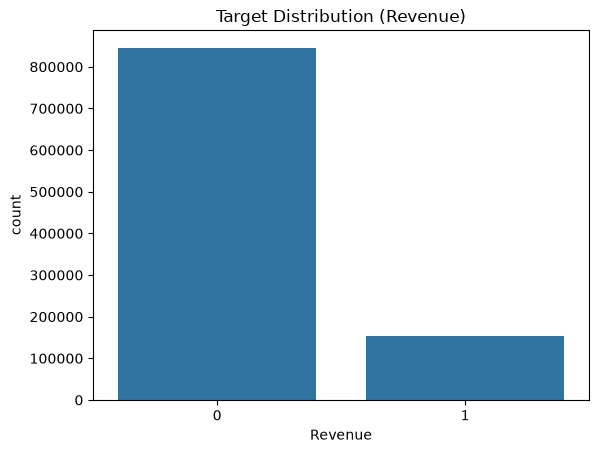

In [8]:
# Basic type adjustments (bool -> int)
shop_data['Revenue'] = shop_data['Revenue'].astype(int)
shop_data['Weekend'] = shop_data['Weekend'].astype(int)

print(shop_data['Revenue'].value_counts(normalize=True).round(3))
sns.countplot(data=shop_data, x='Revenue')
plt.title('Target Distribution (Revenue)')
plt.show()

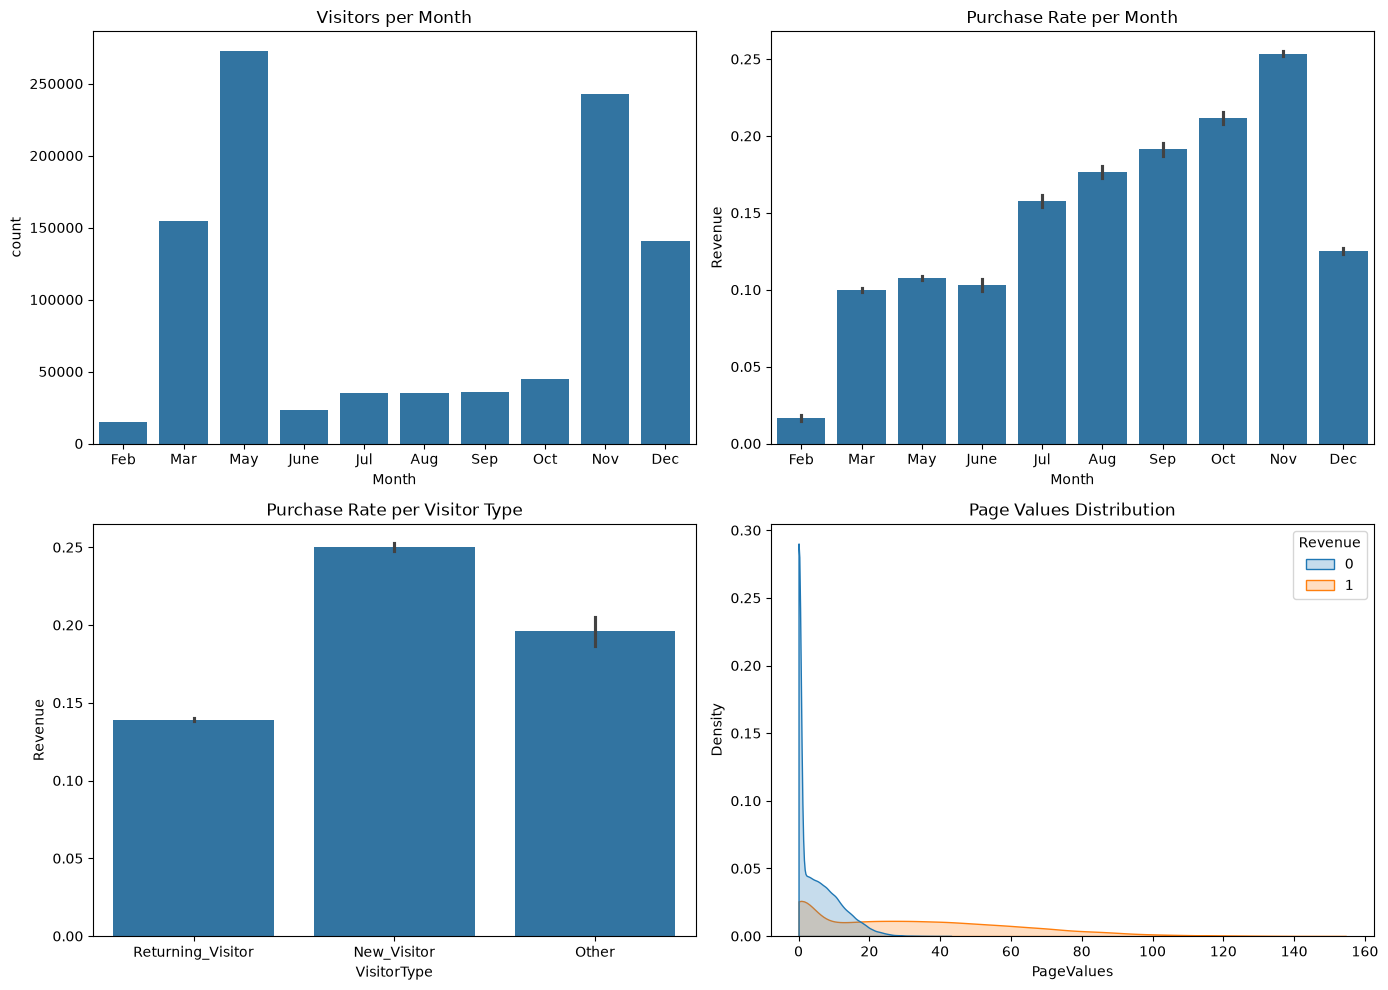

In [9]:
# Exploratory Data Analysis & Visual Insights
all_months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
month_order = [m for m in all_months if m in shop_data['Month'].unique()]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Visitors per month
sns.countplot(data=shop_data, x='Month', order=month_order, ax=axes[0, 0])
axes[0, 0].set_title('Visitors per Month')

# Purchase rate per month (أهم من العدد لوحده)
sns.barplot(data=shop_data, x='Month', y='Revenue', order=month_order, ax=axes[0, 1])
axes[0, 1].set_title('Purchase Rate per Month')

# Purchase rate per visitor type
sns.barplot(data=shop_data, x='VisitorType', y='Revenue', ax=axes[1, 0])
axes[1, 0].set_title('Purchase Rate per Visitor Type')

# PageValues distribution (KDE) - على sample عشان الداتا مليون صف
sample = shop_data.sample(min(len(shop_data), 100_000), random_state=42)
sns.kdeplot(data=sample, x='PageValues', hue='Revenue', common_norm=False, fill=True, clip=(0, None), ax=axes[1, 1])
axes[1, 1].set_title('Page Values Distribution')

plt.tight_layout()
plt.show()

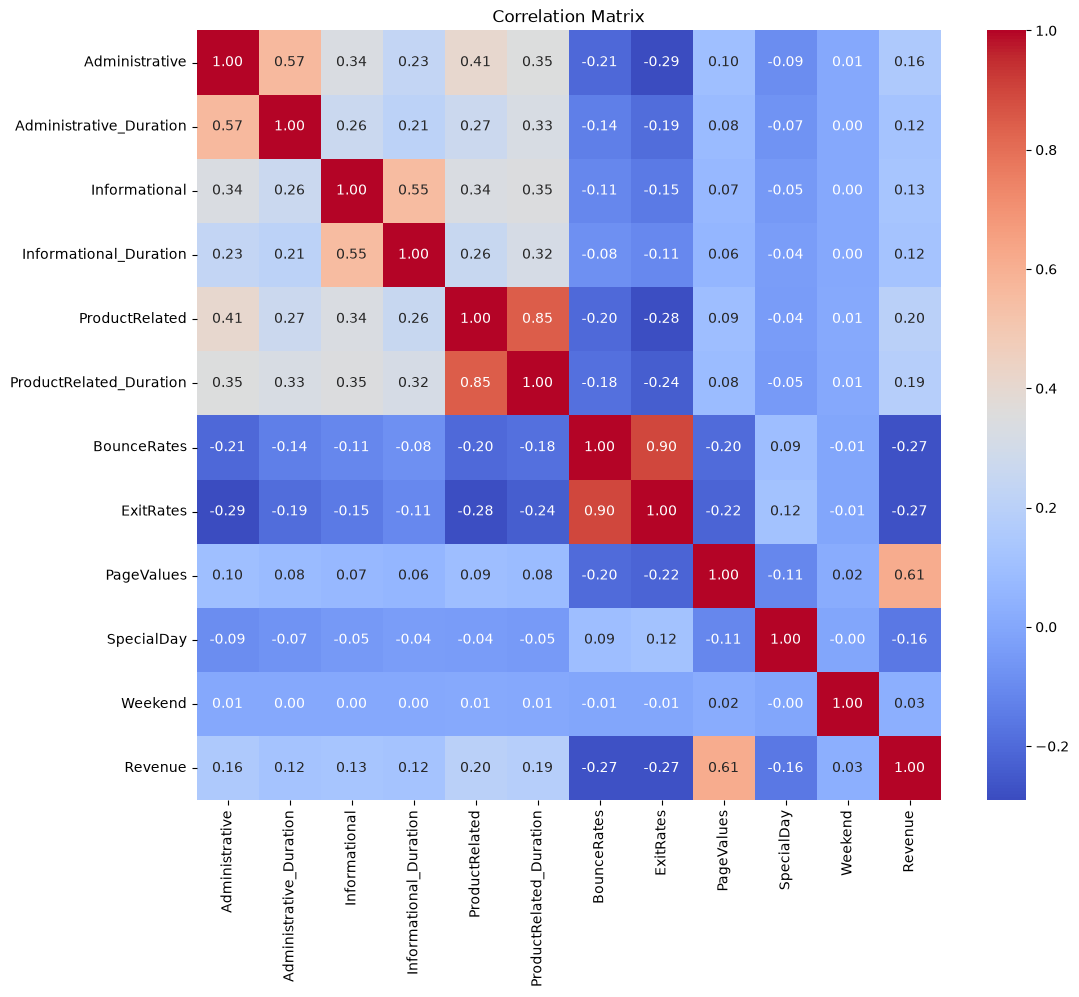

Revenue                    1.000000
PageValues                 0.612852
ProductRelated             0.203031
ProductRelated_Duration    0.185379
Administrative             0.155501
Informational              0.129545
Administrative_Duration    0.118879
Informational_Duration     0.118060
Weekend                    0.031467
SpecialDay                -0.158855
ExitRates                 -0.272886
BounceRates               -0.273894
Name: Revenue, dtype: float64


In [10]:
# Correlation heatmap
id_like = ['OperatingSystems', 'Browser', 'Region', 'TrafficType']
numeric_cols = [c for c in shop_data.select_dtypes(include=[np.number]).columns if c not in id_like]

plt.figure(figsize=(12, 10))
sns.heatmap(shop_data[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

print(shop_data[numeric_cols].corr()['Revenue'].sort_values(ascending=False))

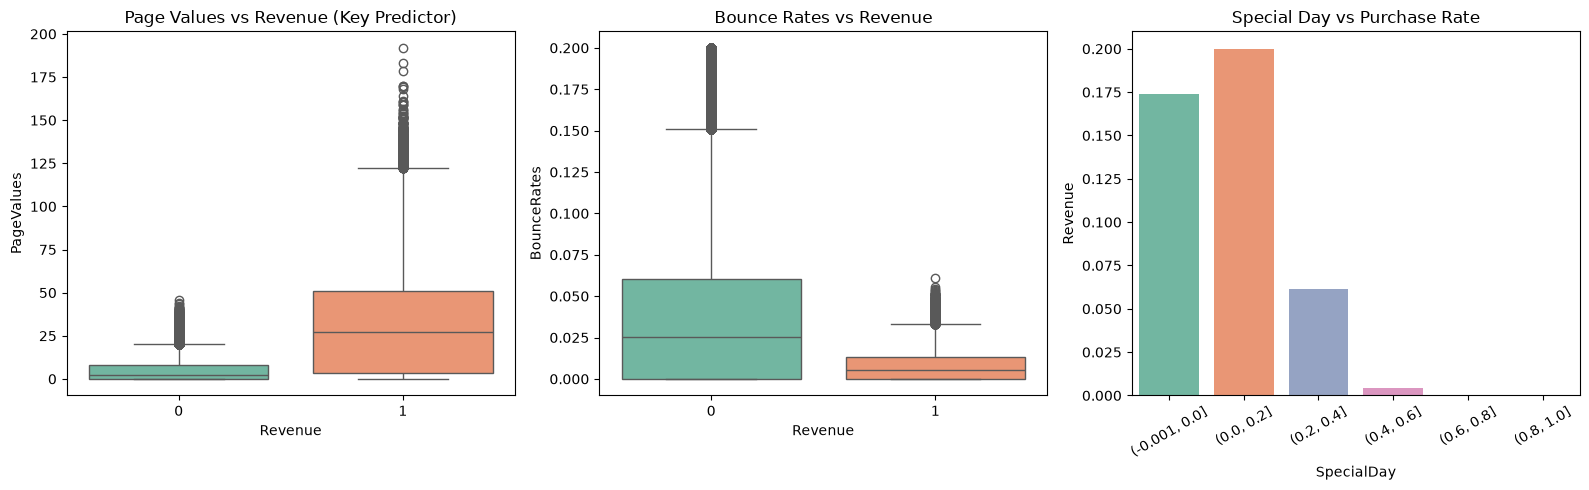

In [11]:
# Key predictors vs Revenue
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(data=shop_data, x='Revenue', y='PageValues', hue='Revenue', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Page Values vs Revenue (Key Predictor)')

sns.boxplot(data=shop_data, x='Revenue', y='BounceRates', hue='Revenue', palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('Bounce Rates vs Revenue')

# بنقسمها لـ bins ونعرض Purchase Rate لكل bin
special_bins = pd.cut(shop_data['SpecialDay'], bins=[-0.001, 0, 0.2, 0.4, 0.6, 0.8, 1.0]).astype(str)
rate = shop_data.groupby(special_bins)['Revenue'].mean().reset_index()
sns.barplot(data=rate, x='SpecialDay', y='Revenue', ax=axes[2], palette='Set2')
axes[2].set_title('Special Day vs Purchase Rate')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

In [12]:
# Save cleaned data
shop_data = shop_data.drop_duplicates().reset_index(drop=True)
shop_data.to_csv('cleaned_data.csv', index=False)
print("Saved as 'cleaned_data.csv' | shape:", shop_data.shape)

Saved as 'cleaned_data.csv' | shape: (999990, 18)
